In [2]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras as keras_original
import tf_keras as keras_qat
import tensorflow_model_optimization as tfmot

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

RAIZ = Path.cwd()
MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados_comparacion_qat"
RESULTADOS.mkdir(parents=True, exist_ok=True)

if not MODELOS.is_dir():
    raise FileNotFoundError(
        f"No existe {MODELOS}. Abre el notebook desde "
        "Red_clasificacion_Radiografias."
    )


def buscar_modelo(*nombres):
    """Busca primero el nombre habitual y luego alternativas explícitas."""
    for nombre in nombres:
        ruta = MODELOS / nombre
        if ruta.is_file():
            return ruta

    raise FileNotFoundError(
        f"No se encontró ninguno de estos archivos en {MODELOS}: "
        f"{nombres}"
    )


RUTA_FLOAT_KERAS = buscar_modelo("CNN_Float32.keras")

RUTA_PTQ = buscar_modelo(
    "CNN_PTQ_INT8.tflite",
)

RUTA_INT16 = buscar_modelo(
    "CNN_INT16x8.tflite",
)

RUTA_MIX3 = buscar_modelo(
    "CNN_PTQ_MIXED_SELECTIVE_3_NODES.tflite"
)
RUTA_MIX5 = buscar_modelo(
    "CNN_PTQ_MIXED_SELECTIVE_5_NODES.tflite"
)

RUTA_QAT = MODELOS / "CNN_QAT_INT8.tflite"
RUTA_FLOAT_TFLITE = MODELOS / "CNN_Float32_comparacion.tflite"

print("TensorFlow:", tf.__version__)
print("Keras original:", keras_original.__version__)
print("tf_keras:", keras_qat.__version__)
print("TFMOT:", tfmot.__version__)
print("Directorio:", RAIZ)

for ruta in [
    RUTA_FLOAT_KERAS, RUTA_PTQ, RUTA_INT16,
    RUTA_MIX3, RUTA_MIX5,
]:
    print("Modelo:", ruta.name)

TensorFlow: 2.21.0
Keras original: 3.12.4
tf_keras: 2.21.0
TFMOT: 0.8.1
Directorio: C:\Users\Alonso\Jupyter\Tesis\Test_Modelos_Cuantizacion\Red_clasificacion_Imagenes\Red_clasificacion_Radiografias
Modelo: CNN_Float32.keras
Modelo: CNN_PTQ_INT8.tflite
Modelo: CNN_INT16x8.tflite
Modelo: CNN_PTQ_MIXED_SELECTIVE_3_NODES.tflite
Modelo: CNN_PTQ_MIXED_SELECTIVE_5_NODES.tflite


In [3]:
def cargar_imagenes(nombre):
    x = np.load(RAIZ / nombre).astype(np.float32)

    if x.ndim == 3:
        x = x[..., np.newaxis]

    if x.ndim != 4 or x.shape[1:] != (150, 150, 1):
        raise ValueError(f"{nombre}: forma inesperada {x.shape}")

    if not np.isfinite(x).all():
        raise ValueError(f"{nombre}: contiene NaN o infinitos.")

    if x.min() < -1e-6 or x.max() > 1.0 + 1e-6:
        raise ValueError(
            f"{nombre}: rango [{x.min()}, {x.max()}]. "
            "Se esperaban imágenes previamente normalizadas a [0, 1]."
        )

    return x


def cargar_etiquetas(nombre):
    y = np.load(RAIZ / nombre).reshape(-1)

    if not np.isin(y, [0, 1]).all():
        raise ValueError(f"{nombre}: se esperaban etiquetas 0 y 1.")

    return y.astype(np.int32)


X_train_qat = cargar_imagenes("xtrain.npy")
X_test_eval = cargar_imagenes("xtest.npy")

y_train_qat = cargar_etiquetas("ytrain.npy")
y_test_eval = cargar_etiquetas("ytest.npy")

assert len(X_train_qat) == len(y_train_qat)
assert len(X_test_eval) == len(y_test_eval)

indices_ajuste, indices_validacion = train_test_split(
    np.arange(len(y_train_qat)),
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_qat,
)

print("Muestras para ajuste QAT:", len(indices_ajuste))
print("Muestras para validación QAT:", len(indices_validacion))
print("Muestras de test final:", len(y_test_eval))
print("Clases de test:", np.bincount(y_test_eval, minlength=2))

Muestras para ajuste QAT: 2279
Muestras para validación QAT: 403
Muestras de test final: 624
Clases de test: [234 390]


In [4]:
modelo_base_original = keras_original.models.load_model(
    RUTA_FLOAT_KERAS,
    compile=False,
)

L = keras_qat.layers

modelo_base_qat = keras_qat.Sequential([
    L.InputLayer(input_shape=(150, 150, 1)),

    L.Conv2D(6, (3, 3), activation="relu"),
    L.MaxPooling2D((2, 2)),

    L.Conv2D(6, (3, 3), activation="relu"),
    L.MaxPooling2D((2, 2)),

    L.Conv2D(6, (3, 3), activation="relu"),
    L.MaxPooling2D((2, 2)),

    L.Conv2D(6, (3, 3), activation="relu"),

    L.Flatten(),
    L.Dense(16, activation="relu"),
    L.Dense(2, activation="sigmoid"),
])

# Copiar pesos entrenados; no iniciar desde pesos aleatorios.
modelo_base_qat.set_weights(modelo_base_original.get_weights())

# Comprobar equivalencia ANTES de introducir fake quantization.
muestra_equivalencia = X_train_qat[indices_validacion[:8]]

salida_original = modelo_base_original(
    muestra_equivalencia, training=False
).numpy()

salida_copia = modelo_base_qat(
    muestra_equivalencia, training=False
).numpy()

np.testing.assert_allclose(
    salida_original,
    salida_copia,
    rtol=1e-4,
    atol=1e-5,
)

print(
    "Error máximo al transferir pesos:",
    np.max(np.abs(salida_original - salida_copia)),
)

modelo_qat = tfmot.quantization.keras.quantize_model(
    modelo_base_qat
)

modelo_qat.compile(
    optimizer=keras_qat.optimizers.Adam(learning_rate=1e-5),
    loss=keras_qat.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

modelo_qat.summary()



Error máximo al transferir pesos: 0.0
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 quantize_layer (QuantizeLa  (None, 150, 150, 1)       3         
 yer)                                                            
                                                                 
 quant_conv2d (QuantizeWrap  (None, 148, 148, 6)       75        
 perV2)                                                          
                                                                 
 quant_max_pooling2d (Quant  (None, 74, 74, 6)         1         
 izeWrapperV2)                                                   
                                                                 
 quant_conv2d_1 (QuantizeWr  (None, 72, 72, 6)         345       
 apperV2)                                                        
                                                                 
 quant_max_pooli

Epoch 1/15


72/72 [==============================] - 6s 42ms/step - loss: 0.1202 - accuracy: 0.9557 - val_loss: 0.1087 - val_accuracy: 0.9553 - lr: 1.0000e-05
Epoch 2/15
72/72 [==============================] - 3s 36ms/step - loss: 0.1202 - accuracy: 0.9570 - val_loss: 0.1080 - val_accuracy: 0.9578 - lr: 1.0000e-05
Epoch 3/15
72/72 [==============================] - 3s 37ms/step - loss: 0.1175 - accuracy: 0.9557 - val_loss: 0.1122 - val_accuracy: 0.9553 - lr: 1.0000e-05
Epoch 4/15
72/72 [==============================] - 3s 36ms/step - loss: 0.1157 - accuracy: 0.9583 - val_loss: 0.1024 - val_accuracy: 0.9529 - lr: 1.0000e-05
Epoch 5/15
72/72 [==============================] - 3s 36ms/step - loss: 0.1141 - accuracy: 0.9592 - val_loss: 0.1081 - val_accuracy: 0.9504 - lr: 1.0000e-05
Epoch 6/15
71/72 [============================>.] - ETA: 0s - loss: 0.1135 - accuracy: 0.9564
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
72/72 [==============================]

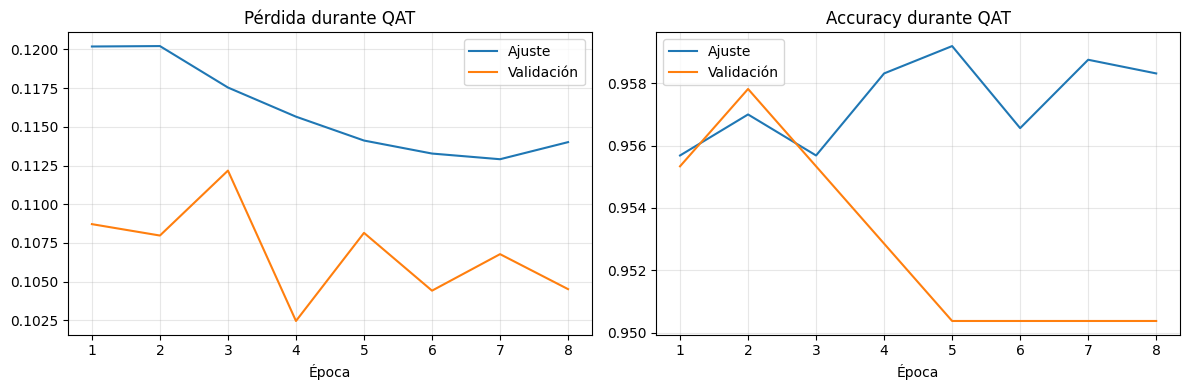

In [5]:
EPOCAS_QAT = 15
BATCH_SIZE_QAT = 32

callbacks_qat = [
    keras_qat.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    keras_qat.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

historial_qat = modelo_qat.fit(
    X_train_qat[indices_ajuste],
    y_train_qat[indices_ajuste],
    validation_data=(
        X_train_qat[indices_validacion],
        y_train_qat[indices_validacion],
    ),
    epochs=EPOCAS_QAT,
    batch_size=BATCH_SIZE_QAT,
    shuffle=True,
    callbacks=callbacks_qat,
    verbose=1,
)

df_historial_qat = pd.DataFrame(historial_qat.history)
df_historial_qat.index.name = "epoca_indice_0"
df_historial_qat.to_csv(RESULTADOS / "historial_qat.csv")

modelo_qat.save_weights(
    str(MODELOS / "CNN_QAT_ajustado.weights.h5")
)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
epocas = np.arange(1, len(df_historial_qat) + 1)

for eje, metrica, titulo in zip(
    ejes,
    ["loss", "accuracy"],
    ["Pérdida durante QAT", "Accuracy durante QAT"],
):
    eje.plot(epocas, df_historial_qat[metrica], label="Ajuste")
    eje.plot(
        epocas,
        df_historial_qat[f"val_{metrica}"],
        label="Validación",
    )
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.savefig(RESULTADOS / "curvas_qat.png", dpi=180)
plt.show()

In [6]:
rng_qat = np.random.default_rng(SEED)

indices_calibracion_qat = rng_qat.choice(
    indices_ajuste,
    size=min(350, len(indices_ajuste)),
    replace=False,
)


def representative_dataset_qat():
    for indice in indices_calibracion_qat:
        yield [X_train_qat[indice:indice + 1]]


# QAT: convertir la red ya ajustada, NO el Float32 original.
convertidor_qat = tf.lite.TFLiteConverter.from_keras_model(
    modelo_qat
)

convertidor_qat.optimizations = [tf.lite.Optimize.DEFAULT]
convertidor_qat.representative_dataset = representative_dataset_qat

convertidor_qat.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

convertidor_qat.inference_input_type = tf.int8
convertidor_qat.inference_output_type = tf.int8

RUTA_QAT.write_bytes(convertidor_qat.convert())

# Referencia Float32 con los pesos originales, sin ajuste QAT.
convertidor_float = tf.lite.TFLiteConverter.from_keras_model(
    modelo_base_qat
)
convertidor_float.optimizations = []

RUTA_FLOAT_TFLITE.write_bytes(convertidor_float.convert())

# Verificación del modelo QAT exportado.
verificador = tf.lite.Interpreter(model_path=str(RUTA_QAT))
verificador.allocate_tensors()

entrada = verificador.get_input_details()[0]
salida = verificador.get_output_details()[0]

assert entrada["dtype"] == np.int8
assert salida["dtype"] == np.int8
assert entrada["quantization"][0] > 0
assert salida["quantization"][0] > 0

tensores_float = [
    d["name"]
    for d in verificador.get_tensor_details()
    if np.issubdtype(d["dtype"], np.floating)
]

if tensores_float:
    raise RuntimeError(
        f"El modelo QAT conserva tensores flotantes: {tensores_float}"
    )

print("QAT guardado:", RUTA_QAT)
print("Entrada:", entrada["dtype"], entrada["quantization"])
print("Salida:", salida["dtype"], salida["quantization"])
print("Tamaño QAT:", RUTA_QAT.stat().st_size, "bytes")

del verificador

INFO:tensorflow:Assets written to: C:\Users\Alonso\AppData\Local\Temp\tmpkan_y2na\assets


INFO:tensorflow:Assets written to: C:\Users\Alonso\AppData\Local\Temp\tmpkan_y2na\assets
C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\Alonso\AppData\Local\Temp\tmplvrqjl6t\assets


INFO:tensorflow:Assets written to: C:\Users\Alonso\AppData\Local\Temp\tmplvrqjl6t\assets


QAT guardado: C:\Users\Alonso\Jupyter\Tesis\Test_Modelos_Cuantizacion\Red_clasificacion_Imagenes\Red_clasificacion_Radiografias\modelos\CNN_QAT_INT8.tflite
Entrada: <class 'numpy.int8'> (0.003921568859368563, -128)
Salida: <class 'numpy.int8'> (0.00390625, -128)
Tamaño QAT: 29784 bytes


C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [7]:
NUM_THREADS = 4
CALENTAMIENTO = 10
CLASES = ["NORMAL", "PNEUMONIA"]


def preparar_entrada(imagen, detalle):
    x = imagen[np.newaxis].astype(np.float32)
    dtype = detalle["dtype"]

    if np.issubdtype(dtype, np.integer):
        escala, cero = detalle["quantization"]

        if escala <= 0:
            raise ValueError("Escala de entrada no válida.")

        limites = np.iinfo(dtype)
        x = np.clip(
            np.rint(x / escala + cero),
            limites.min,
            limites.max,
        )

    return x.astype(dtype)


def recuperar_salida(interprete, detalle):
    y = interprete.get_tensor(detalle["index"]).astype(np.float32)

    if np.issubdtype(detalle["dtype"], np.integer):
        escala, cero = detalle["quantization"]

        if escala <= 0:
            raise ValueError("Escala de salida no válida.")

        y = (y - cero) * escala

    y = y.reshape(-1)

    if y.size != 2:
        raise ValueError(f"Se esperaban dos salidas; se obtuvo {y.shape}.")

    return y


def evaluar_tflite(nombre, ruta, X, y):
    interprete = tf.lite.Interpreter(
        model_path=str(ruta),
        num_threads=NUM_THREADS,
    )
    interprete.allocate_tensors()

    entradas = interprete.get_input_details()
    salidas = interprete.get_output_details()

    assert len(entradas) == 1 and len(salidas) == 1

    entrada = entradas[0]
    salida = salidas[0]

    assert tuple(entrada["shape"]) == (1, 150, 150, 1)

    # Calentamiento: no modifica pesos ni forma parte del entrenamiento.
    interprete.set_tensor(
        entrada["index"],
        preparar_entrada(X[0], entrada),
    )

    for _ in range(CALENTAMIENTO):
        interprete.invoke()

    scores = np.empty((len(X), 2), dtype=np.float32)
    tiempos_ms = np.empty(len(X), dtype=np.float64)

    for i, imagen in enumerate(X):
        interprete.set_tensor(
            entrada["index"],
            preparar_entrada(imagen, entrada),
        )

        inicio = perf_counter()
        interprete.invoke()
        tiempos_ms[i] = (perf_counter() - inicio) * 1000

        scores[i] = recuperar_salida(interprete, salida)

        if (i + 1) % 100 == 0 or i + 1 == len(X):
            print(f"\r{nombre}: {i + 1}/{len(X)}", end="")

    print()

    pred = np.argmax(scores, axis=1)
    matriz = confusion_matrix(y, pred, labels=[0, 1])
    tn, fp, fn, tp = matriz.ravel()

    metricas = {
        "Modelo": nombre,
        "N_test": len(y),
        "Accuracy": accuracy_score(y, pred),
        "Balanced_accuracy": balanced_accuracy_score(y, pred),
        "Precision": precision_score(
            y, pred, pos_label=1, zero_division=0
        ),
        "Recall_sensibilidad": recall_score(
            y, pred, pos_label=1, zero_division=0
        ),
        "Especificidad": tn / (tn + fp) if tn + fp else np.nan,
        "F1": f1_score(y, pred, pos_label=1, zero_division=0),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TFLite_bytes": ruta.stat().st_size,
        "TFLite_KiB": ruta.stat().st_size / 1024,
        "Latencia_host_media_ms": tiempos_ms.mean(),
        "Latencia_host_mediana_ms": np.median(tiempos_ms),
        "Latencia_host_std_ms": tiempos_ms.std(),
        "Latencia_host_p95_ms": np.percentile(tiempos_ms, 95),
        "Entrada_dtype": np.dtype(entrada["dtype"]).name,
        "Salida_dtype": np.dtype(salida["dtype"]).name,
    }

    return metricas, matriz, pred, scores

In [8]:
rutas_comparacion = {
    "Float32": RUTA_FLOAT_TFLITE,
    "PTQ INT8": RUTA_PTQ,
    "INT16x8": RUTA_INT16,
    "Mixed-3": RUTA_MIX3,
    "Mixed-5": RUTA_MIX5,
    "QAT INT8": RUTA_QAT,
}

filas_metricas = []
matrices = {}
predicciones = {}
salidas_modelos = {}

for nombre, ruta in rutas_comparacion.items():
    metricas, matriz, pred, scores = evaluar_tflite(
        nombre,
        ruta,
        X_test_eval,
        y_test_eval,
    )

    filas_metricas.append(metricas)
    matrices[nombre] = matriz
    predicciones[nombre] = pred
    salidas_modelos[nombre] = scores

    identificador = nombre.replace(" ", "_").replace("-", "_")

    pd.DataFrame(
        matriz,
        index=[f"Real_{c}" for c in CLASES],
        columns=[f"Pred_{c}" for c in CLASES],
    ).to_csv(RESULTADOS / f"matriz_{identificador}.csv")

    reporte = classification_report(
        y_test_eval,
        pred,
        labels=[0, 1],
        target_names=CLASES,
        output_dict=True,
        zero_division=0,
    )

    pd.DataFrame(reporte).T.to_csv(
        RESULTADOS / f"reporte_{identificador}.csv"
    )

    np.savez_compressed(
        RESULTADOS / f"predicciones_{identificador}.npz",
        y_real=y_test_eval,
        y_pred=pred,
        salidas=scores,
    )

df_resultados = pd.DataFrame(filas_metricas)

tamano_base = RUTA_FLOAT_TFLITE.stat().st_size
df_resultados["Compresion_%"] = (
    100 * (1 - df_resultados["TFLite_bytes"] / tamano_base)
)

# Error de salidas respecto de Float32.
# En QAT incluye el efecto del reajuste de pesos, no solo cuantización.
referencia = salidas_modelos["Float32"].astype(np.float64)

df_resultados["RMSE_salida_vs_Float32"] = [
    np.sqrt(np.mean(
        (salidas_modelos[nombre].astype(np.float64) - referencia) ** 2
    ))
    for nombre in df_resultados["Modelo"]
]

df_resultados.to_csv(
    RESULTADOS / "comparacion_final_modelos.csv",
    index=False,
    encoding="utf-8-sig",
)

# Mostrar métricas como porcentajes sin alterar el CSV base.
columnas_porcentaje = [
    "Accuracy",
    "Balanced_accuracy",
    "Precision",
    "Recall_sensibilidad",
    "Especificidad",
    "F1",
]

df_mostrar = df_resultados.copy()
df_mostrar[columnas_porcentaje] *= 100

display(df_mostrar.round(4))
print("Resultados guardados en:", RESULTADOS)

Float32: 624/624
PTQ INT8: 100/624

C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


PTQ INT8: 624/624


C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INT16x8: 624/624
Mixed-3: 400/624

C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


... (3 outputs left out)

C:\Users\Alonso\.conda\envs\CNN\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


QAT INT8: 624/624


,Modelo,N_test,Accuracy,Balanced_accuracy,Precision,Recall_sensibilidad,Especificidad,F1,TN,FP,...,TFLite_bytes,TFLite_KiB,Latencia_host_media_ms,Latencia_host_mediana_ms,Latencia_host_std_ms,Latencia_host_p95_ms,Entrada_dtype,Salida_dtype,Compresion_%,RMSE_salida_vs_Float32
0,Float32,624,79.8077,73.6752,76.2948,98.2051,49.1453,85.8744,115,119,...,95652,93.4102,0.1728,0.1563,0.0411,0.2764,float32,float32,0.0000,0.0000
1,PTQ INT8,624,80.9295,75.3419,77.5967,97.6923,52.9915,86.4926,124,110,...,38824,37.9141,0.5312,0.4351,0.8070,0.9134,float32,float32,59.4112,0.5192
2,INT16x8,624,79.1667,72.8205,75.6917,98.2051,47.4359,85.4911,111,123,...,31672,30.9297,9.2579,8.7766,1.1546,12.1279,float32,float32,66.8883,0.0078
3,Mixed-3,624,79.4872,73.2479,75.9921,98.2051,48.2906,85.6823,113,121,...,31968,31.2188,0.2988,0.2869,0.0672,0.4075,int8,int8,66.5788,0.0052
4,Mixed-5,624,79.8077,73.6752,76.2948,98.2051,49.1453,85.8744,115,119,...,34128,33.3281,0.2514,0.2232,0.0639,0.3892,int8,int8,64.3207,0.0038
5,QAT INT8,624,79.9679,74.0598,76.6600,97.6923,50.4274,85.9076,118,116,...,29784,29.0859,0.3725,0.3584,0.0643,0.4659,int8,int8,68.8621,0.0283


Resultados guardados en: C:\Users\Alonso\Jupyter\Tesis\Test_Modelos_Cuantizacion\Red_clasificacion_Imagenes\Red_clasificacion_Radiografias\resultados_comparacion_qat


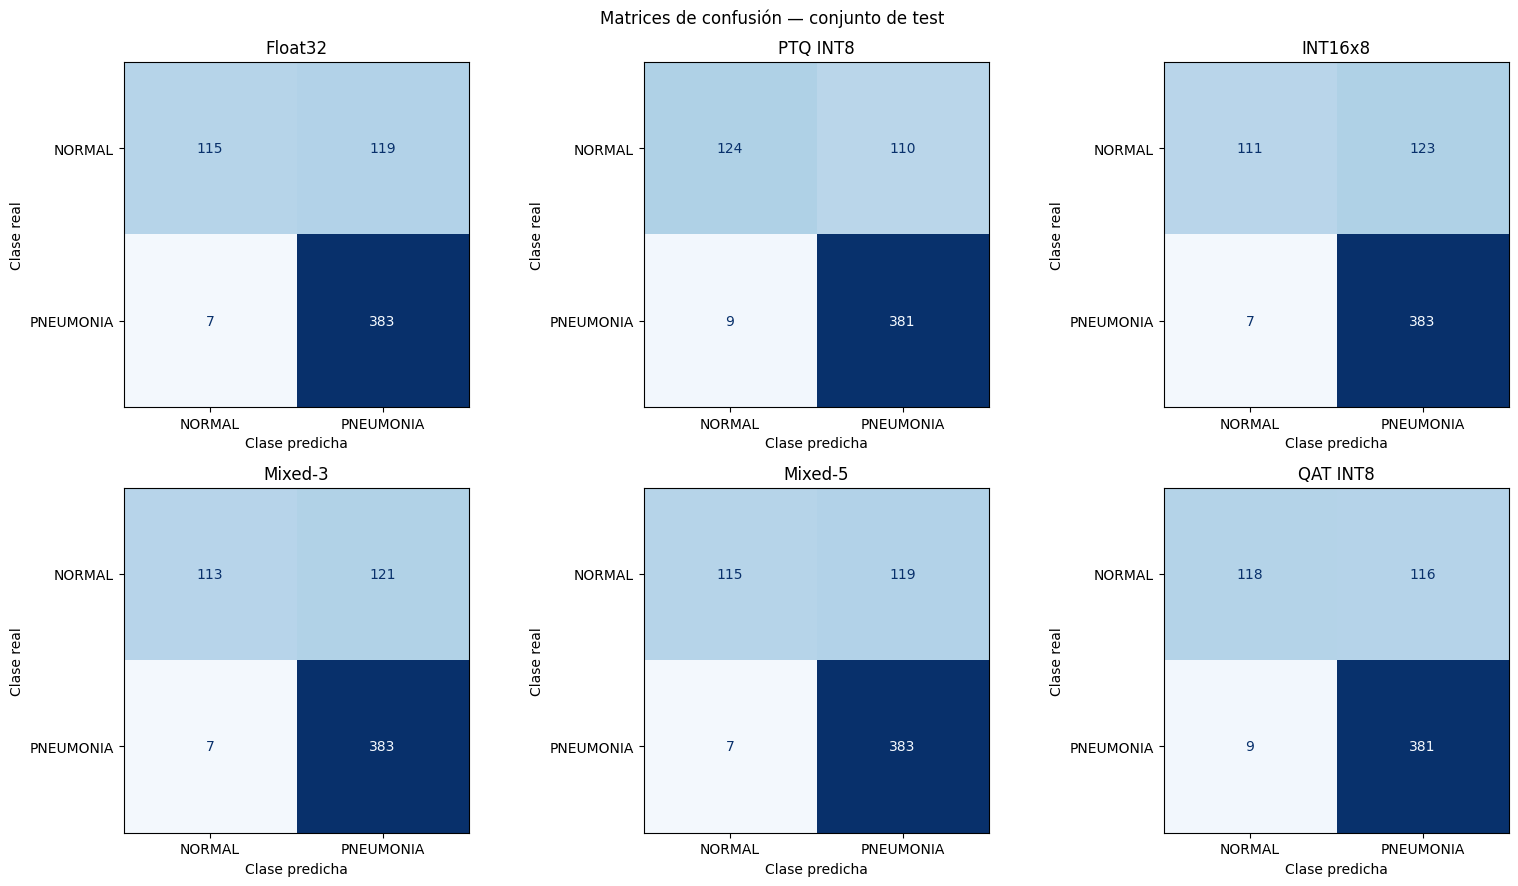

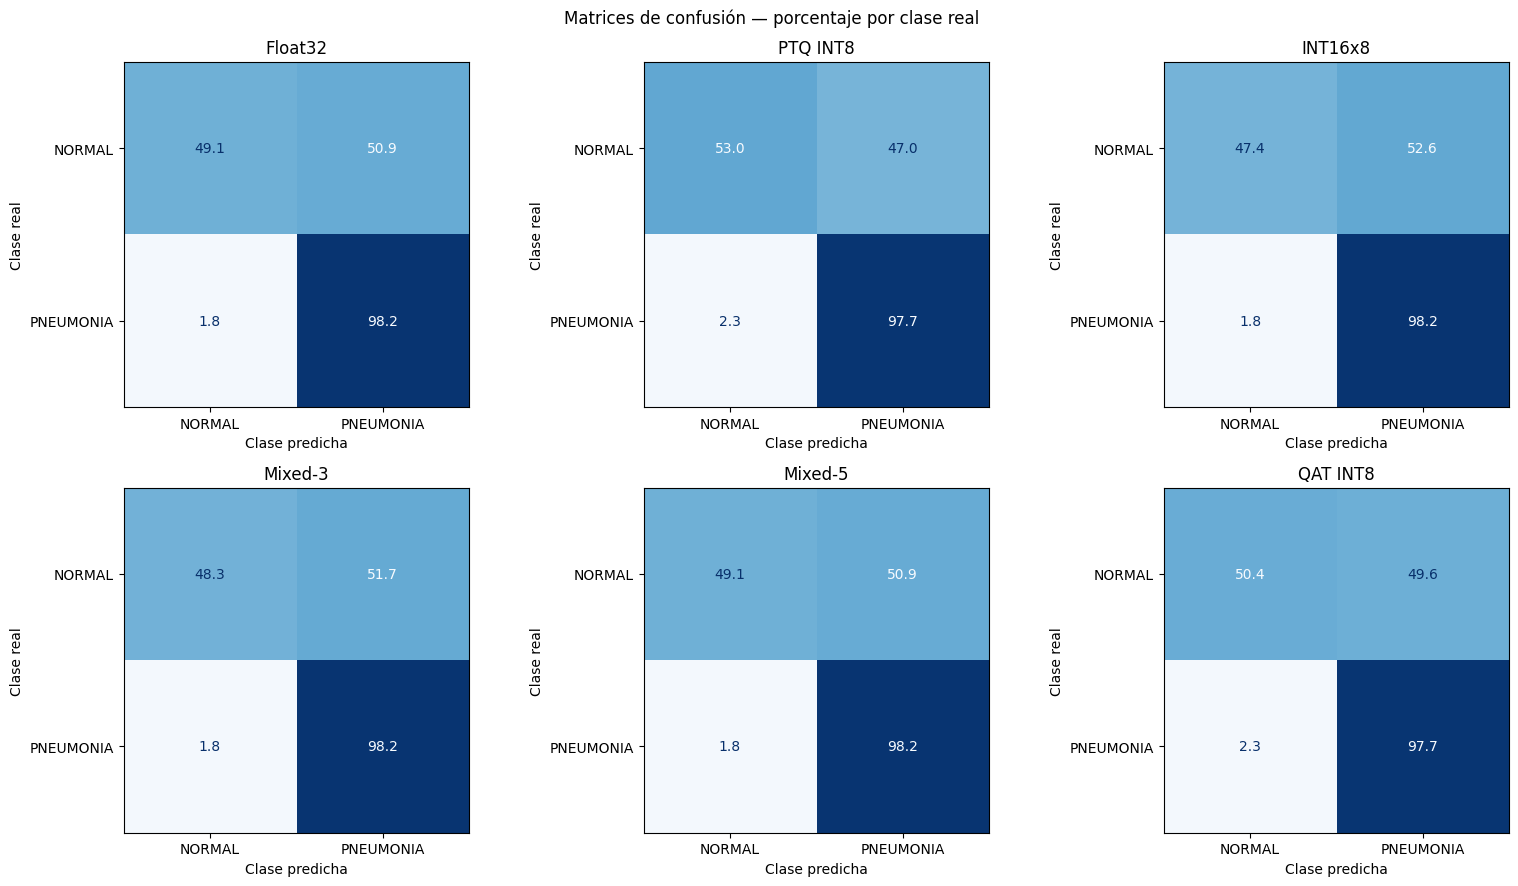

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
maximo = max(int(m.max()) for m in matrices.values())

for eje, (nombre, matriz) in zip(ejes.ravel(), matrices.items()):
    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASES,
    )

    visualizacion.plot(
        ax=eje,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        im_kw={"vmin": 0, "vmax": maximo},
    )

    eje.set_title(nombre)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

fig.suptitle("Matrices de confusión — conjunto de test")
plt.tight_layout()
plt.savefig(
    RESULTADOS / "matrices_confusion_absolutas.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


fig, ejes = plt.subplots(2, 3, figsize=(16, 9))

for eje, (nombre, matriz) in zip(ejes.ravel(), matrices.items()):
    porcentajes = (
        100 * matriz
        / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=porcentajes,
        display_labels=CLASES,
    )

    visualizacion.plot(
        ax=eje,
        cmap="Blues",
        colorbar=False,
        values_format=".1f",
        im_kw={"vmin": 0, "vmax": 100},
    )

    eje.set_title(nombre)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

fig.suptitle("Matrices de confusión — porcentaje por clase real")
plt.tight_layout()
plt.savefig(
    RESULTADOS / "matrices_confusion_porcentajes.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

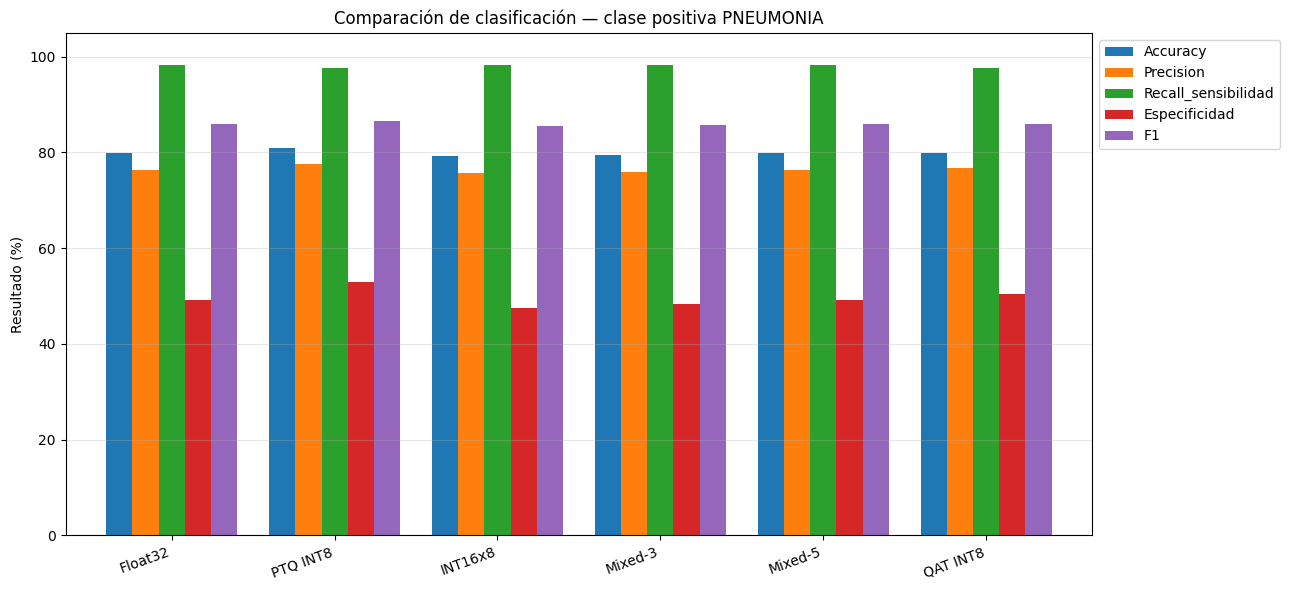

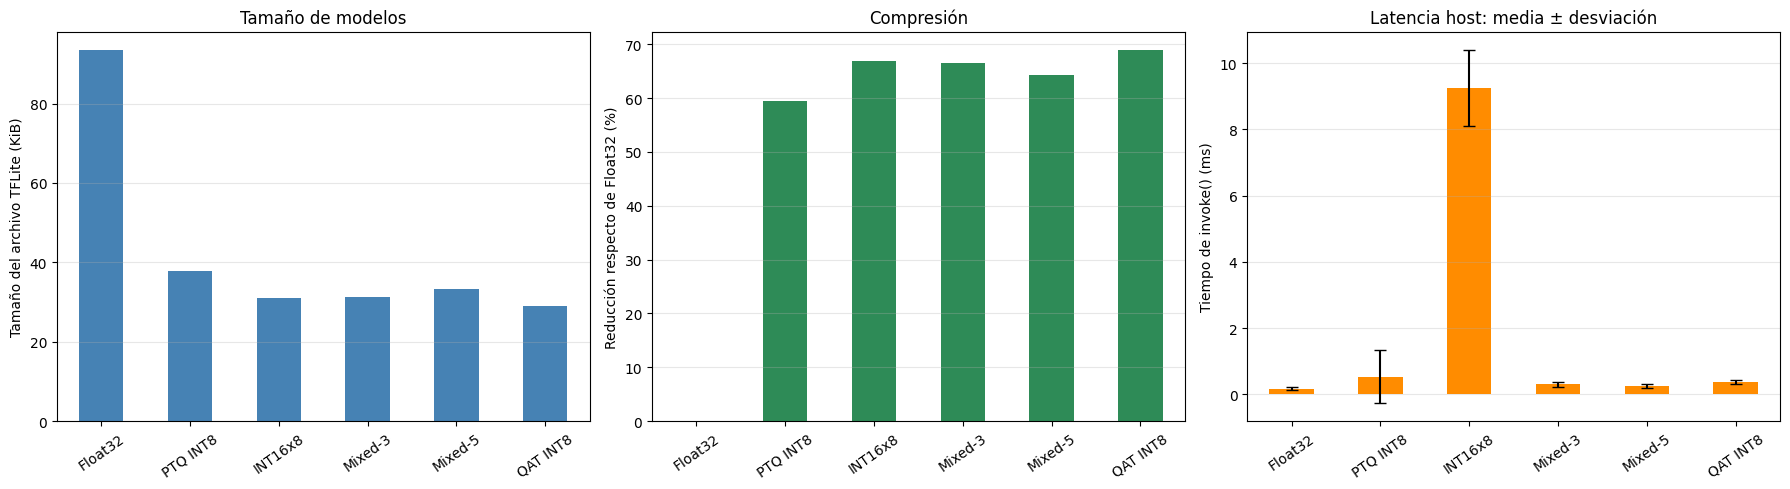

In [10]:
tabla = df_resultados.set_index("Modelo")

metricas_grafico = [
    "Accuracy",
    "Precision",
    "Recall_sensibilidad",
    "Especificidad",
    "F1",
]

eje = (100 * tabla[metricas_grafico]).plot.bar(
    figsize=(13, 6),
    width=0.8,
)

eje.set_ylim(0, 105)
eje.set_ylabel("Resultado (%)")
eje.set_xlabel("")
eje.set_title("Comparación de clasificación — clase positiva PNEUMONIA")
eje.grid(axis="y", alpha=0.3)
eje.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    RESULTADOS / "comparacion_metricas.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

tabla["TFLite_KiB"].plot.bar(
    ax=ejes[0], color="steelblue"
)
ejes[0].set_ylabel("Tamaño del archivo TFLite (KiB)")
ejes[0].set_title("Tamaño de modelos")

tabla["Compresion_%"].plot.bar(
    ax=ejes[1], color="seagreen"
)
ejes[1].set_ylabel("Reducción respecto de Float32 (%)")
ejes[1].set_title("Compresión")

tabla["Latencia_host_media_ms"].plot.bar(
    ax=ejes[2],
    yerr=tabla["Latencia_host_std_ms"],
    capsize=4,
    color="darkorange",
)
ejes[2].set_ylabel("Tiempo de invoke() (ms)")
ejes[2].set_title("Latencia host: media ± desviación")

for eje in ejes:
    eje.set_xlabel("")
    eje.tick_params(axis="x", rotation=35)
    eje.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    RESULTADOS / "comparacion_recursos_host.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()